In [35]:
import pandas as pd

colonnes = ["moteur", "cycle", "reglage_1", "reglage_2", "reglage_3"] + [f"capteur_{i}" for i in range(1, 22)]

train = pd.read_csv("train_FD001.txt", sep=r"\s+", header=None, names=colonnes)

print(train.shape)
train.head()

(20631, 26)


,moteur,cycle,reglage_1,reglage_2,reglage_3,capteur_1,capteur_2,capteur_3,capteur_4,capteur_5,...,capteur_12,capteur_13,capteur_14,capteur_15,capteur_16,capteur_17,capteur_18,capteur_19,capteur_20,capteur_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [36]:
# 1) Taille du jeu de données et nombre de moteurs
print(train.shape)
print("Nombre de moteurs :", train["moteur"].nunique())

# 2) Durée de vie de chaque moteur (nombre de cycles jusqu'à la panne)
duree = train.groupby("moteur")["cycle"].max()
print(duree.describe())

# 3) Calcul de la RUL : cycle max du moteur - cycle courant
train["RUL"] = train.groupby("moteur")["cycle"].transform("max") - train["cycle"]
print(train[["moteur", "cycle", "RUL"]].head())
print(train[["moteur", "cycle", "RUL"]].tail())

# 4) Capteurs constants : écart-type égal ou très proche de 0
ecart_type = train.drop(columns=["moteur", "cycle", "RUL"]).std().sort_values()
print(ecart_type.head(10))


(20631, 26)
Nombre de moteurs : 100
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64
   moteur  cycle  RUL
0       1      1  191
1       1      2  190
2       1      3  189
3       1      4  188
4       1      5  187
       moteur  cycle  RUL
20626     100    196    4
20627     100    197    3
20628     100    198    2
20629     100    199    1
20630     100    200    0
reglage_3     0.000000e+00
capteur_19    0.000000e+00
capteur_18    0.000000e+00
capteur_16    1.556432e-14
capteur_10    4.660829e-13
capteur_5     3.394700e-12
capteur_1     6.537152e-11
reglage_2     2.930621e-04
capteur_6     1.388985e-03
reglage_1     2.187313e-03
dtype: float64


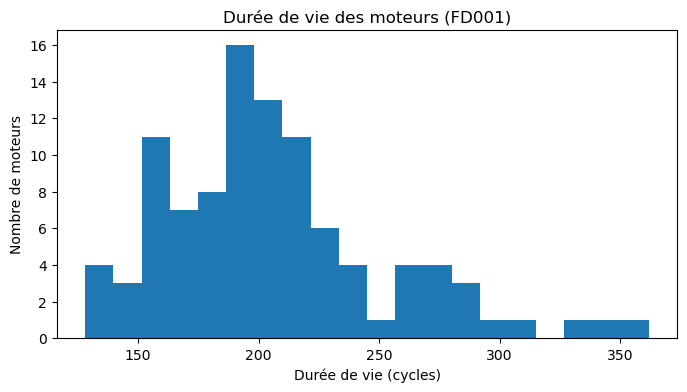

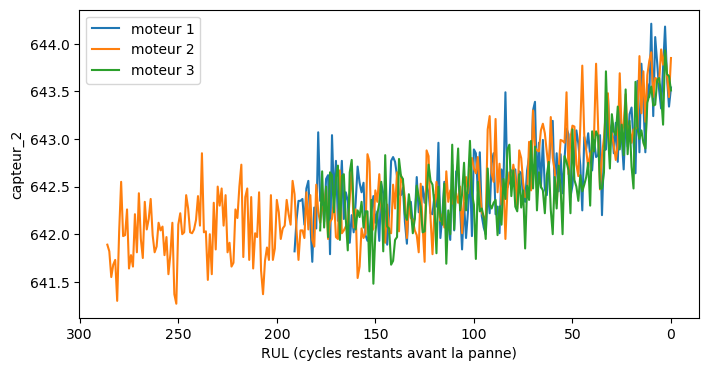

In [37]:
import matplotlib.pyplot as plt

# Durée de vie des 100 moteurs
plt.figure(figsize=(8, 4))
plt.hist(duree, bins=20)
plt.xlabel("Durée de vie (cycles)")
plt.ylabel("Nombre de moteurs")
plt.title("Durée de vie des moteurs (FD001)")
plt.show()

# Évolution d'un capteur pour 3 moteurs, en fonction de la RUL
plt.figure(figsize=(8, 4))
for m in [1, 2, 3]:
    d = train[train["moteur"] == m]
    plt.plot(d["RUL"], d["capteur_2"], label=f"moteur {m}")
plt.gca().invert_xaxis()
plt.xlabel("RUL (cycles restants avant la panne)")
plt.ylabel("capteur_2")
plt.legend()
plt.show()

In [38]:
# 1) Supprimer les colonnes constantes
constantes = ["reglage_3", "capteur_1", "capteur_5", "capteur_10", "capteur_16", "capteur_18", "capteur_19"]
train = train.drop(columns=constantes)

# 2) Liste des variables restantes (hors identifiants et RUL)
variables = [c for c in train.columns if c not in ["moteur", "cycle", "RUL"]]
print(len(variables), "variables restantes")

# 3) Corrélation de chaque variable avec la RUL
correlation = train[variables + ["RUL"]].corr()["RUL"].drop("RUL").sort_values()
print(correlation)

17 variables restantes
capteur_11   -0.696228
capteur_4    -0.678948
capteur_15   -0.642667
capteur_2    -0.606484
capteur_17   -0.606154
capteur_3    -0.584520
capteur_8    -0.563968
capteur_13   -0.562569
capteur_9    -0.390102
capteur_14   -0.306769
capteur_6    -0.128348
reglage_1    -0.003198
reglage_2    -0.001948
capteur_20    0.629428
capteur_21    0.635662
capteur_7     0.657223
capteur_12    0.671983
Name: RUL, dtype: float64


['capteur_11', 'capteur_4', 'capteur_12', 'capteur_7']


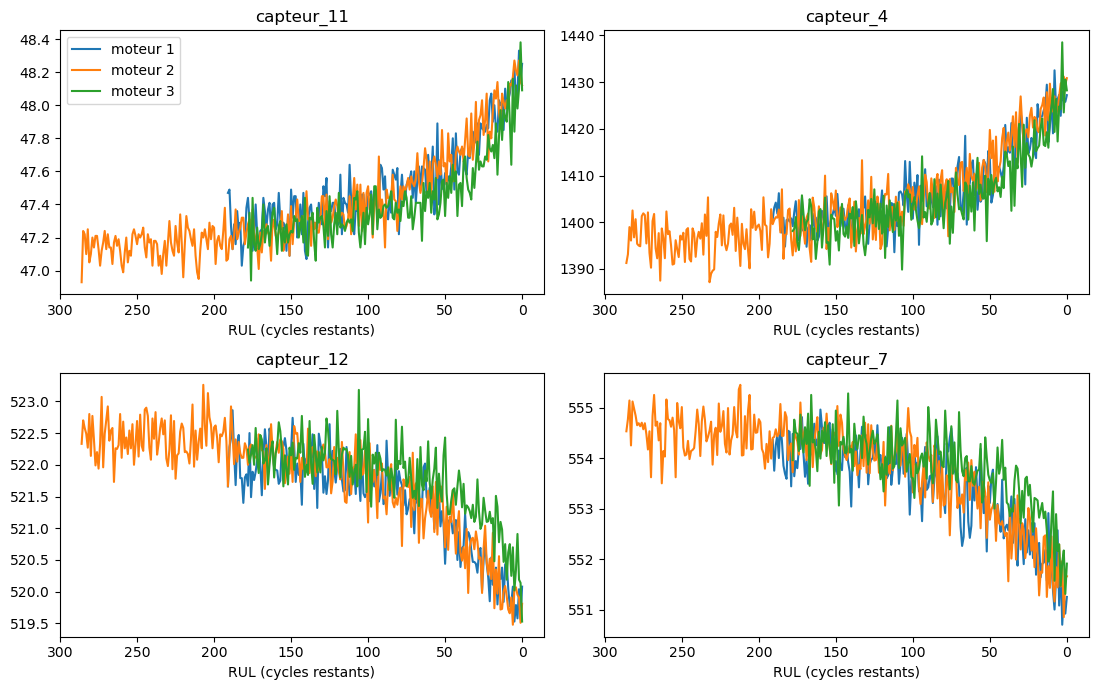

In [39]:
import matplotlib.pyplot as plt

# les 4 variables dont la corrélation est la plus forte (en valeur absolue)
top4 = correlation.abs().sort_values(ascending=False).head(4).index.tolist()
print(top4)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, capteur in zip(axes.ravel(), top4):
    for m in [1, 2, 3]:
        d = train[train["moteur"] == m]
        ax.plot(d["RUL"], d[capteur], label=f"moteur {m}")
    ax.invert_xaxis()
    ax.set_title(capteur)
    ax.set_xlabel("RUL (cycles restants)")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [40]:
# 1) Garder les 14 capteurs retenus
capteurs = ["capteur_2", "capteur_3", "capteur_4", "capteur_7", "capteur_8", "capteur_9",
            "capteur_11", "capteur_12", "capteur_13", "capteur_14", "capteur_15",
            "capteur_17", "capteur_20", "capteur_21"]

# 2) Plafonner la RUL à 125
train["RUL_cap"] = train["RUL"].clip(upper=125)

# 3) Lisser chaque capteur par moteur (moyenne glissante sur 10 cycles)
lisse = train.groupby("moteur")[capteurs].transform(lambda s: s.rolling(10, min_periods=1).mean())
lisse.columns = [c + "_lisse" for c in capteurs]
train = pd.concat([train, lisse], axis=1)

# 4) Nouvelle corrélation avec la RUL plafonnée
corr_cap = train[capteurs + ["RUL_cap"]].corr()["RUL_cap"].drop("RUL_cap").sort_values()
print(corr_cap)

capteur_11   -0.775230
capteur_4    -0.757157
capteur_15   -0.720858
capteur_17   -0.680829
capteur_2    -0.678458
capteur_3    -0.655030
capteur_8    -0.624568
capteur_13   -0.624034
capteur_9    -0.462151
capteur_14   -0.369753
capteur_20    0.704626
capteur_21    0.707334
capteur_7     0.733021
capteur_12    0.748870
Name: RUL_cap, dtype: float64


In [41]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

variables_lisses = [c + "_lisse" for c in capteurs]

# 1) Mettre 20 moteurs de côté pour la validation
ids = train["moteur"].unique()
rng = np.random.default_rng(42)
ids_valid = rng.choice(ids, size=20, replace=False)

valid = train[train["moteur"].isin(ids_valid)]
entr = train[~train["moteur"].isin(ids_valid)]

X_entr, y_entr = entr[variables_lisses], entr["RUL_cap"]
X_valid, y_valid = valid[variables_lisses], valid["RUL_cap"]

# 2) Entraîner la régression linéaire
modele = LinearRegression().fit(X_entr, y_entr)
pred = modele.predict(X_valid)

# 3) Mesurer l'erreur
rmse = np.sqrt(mean_squared_error(y_valid, pred))
rmse_naif = np.sqrt(mean_squared_error(y_valid, np.full(len(y_valid), y_entr.mean())))
print("Erreur du modèle (cycles)  :", round(rmse, 1))
print("Erreur du modèle naïf      :", round(rmse_naif, 1))

Erreur du modèle (cycles)  : 21.6
Erreur du modèle naïf      : 41.6


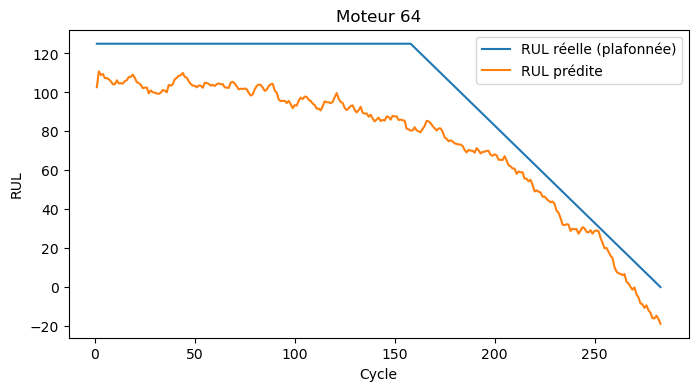

In [42]:
import matplotlib.pyplot as plt

m = ids_valid[0]
masque = (valid["moteur"] == m).values
plt.figure(figsize=(8, 4))
plt.plot(valid.loc[masque, "cycle"], y_valid[masque], label="RUL réelle (plafonnée)")
plt.plot(valid.loc[masque, "cycle"], pred[masque], label="RUL prédite")
plt.xlabel("Cycle")
plt.ylabel("RUL")
plt.title(f"Moteur {m}")
plt.legend()
plt.show()

In [43]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

def rmse_borne(y_vrai, y_pred):
    # on borne la prédiction entre 0 et 125 (une RUL négative n'a pas de sens)
    y_pred = np.clip(y_pred, 0, 125)
    return np.sqrt(mean_squared_error(y_vrai, y_pred))

# Régression linéaire (avec bornage), pour comparer
rmse_lineaire = rmse_borne(y_valid, pred)

# Random Forest
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(X_entr, y_entr)
pred_rf = rf.predict(X_valid)

# Gradient Boosting
gb = HistGradientBoostingRegressor(random_state=42)
gb.fit(X_entr, y_entr)
pred_gb = gb.predict(X_valid)

print("Régression linéaire :", round(rmse_lineaire, 1))
print("Random Forest       :", round(rmse_borne(y_valid, pred_rf), 1))
print("Gradient Boosting   :", round(rmse_borne(y_valid, pred_gb), 1))

Régression linéaire : 21.3
Random Forest       : 18.9
Gradient Boosting   : 18.8


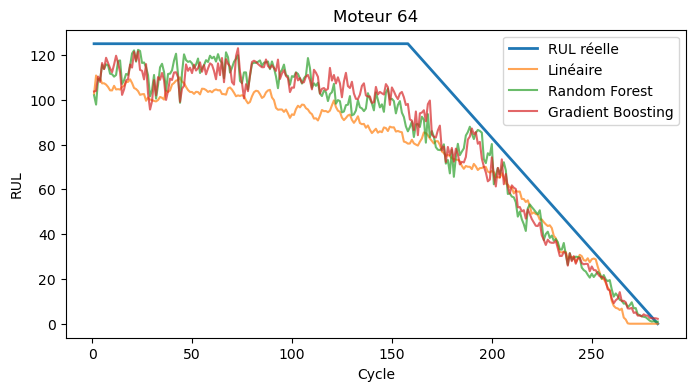

In [44]:
m = 64
masque = (valid["moteur"] == m).values
plt.figure(figsize=(8, 4))
plt.plot(valid.loc[masque, "cycle"], y_valid[masque], label="RUL réelle", linewidth=2)
plt.plot(valid.loc[masque, "cycle"], np.clip(pred[masque], 0, 125), label="Linéaire", alpha=0.7)
plt.plot(valid.loc[masque, "cycle"], np.clip(pred_rf[masque], 0, 125), label="Random Forest", alpha=0.7)
plt.plot(valid.loc[masque, "cycle"], np.clip(pred_gb[masque], 0, 125), label="Gradient Boosting", alpha=0.7)
plt.xlabel("Cycle")
plt.ylabel("RUL")
plt.title(f"Moteur {m}")
plt.legend()
plt.show()

In [45]:
dossier = r"C:\Users\DELL\Downloads\archive"   # à adapter

In [46]:
dossier = "data"

In [47]:
# 1) Charger les données de test et les vraies RUL
test = pd.read_csv("test_FD001.txt", sep=r"\s+", header=None, names=colonnes)
rul_test = pd.read_csv("RUL_FD001.txt", header=None, names=["RUL"])

# 2) Même lissage que pour l'entraînement
lisse_test = test.groupby("moteur")[capteurs].transform(lambda s: s.rolling(10, min_periods=1).mean())
lisse_test.columns = [c + "_lisse" for c in capteurs]
test = pd.concat([test, lisse_test], axis=1)

# 3) Dernier cycle connu de chaque moteur de test
dernier = test.sort_values(["moteur", "cycle"]).groupby("moteur").tail(1)
X_test = dernier[variables_lisses]
y_test = rul_test["RUL"].clip(upper=125).values   # même plafond de 125

# 4) Entraîner sur les 100 moteurs d'entraînement
X_tout, y_tout = train[variables_lisses], train["RUL_cap"]
rf_final = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(X_tout, y_tout)
gb_final = HistGradientBoostingRegressor(random_state=42).fit(X_tout, y_tout)
lin_final = LinearRegression().fit(X_tout, y_tout)

# 5) Prédire et mesurer l'erreur
for nom, mod in [("Linéaire", lin_final), ("Random Forest", rf_final), ("Gradient Boosting", gb_final)]:
    p = np.clip(mod.predict(X_test), 0, 125)
    print(nom, ":", round(np.sqrt(mean_squared_error(y_test, p)), 1))

Linéaire : 22.0
Random Forest : 20.7
Gradient Boosting : 20.3


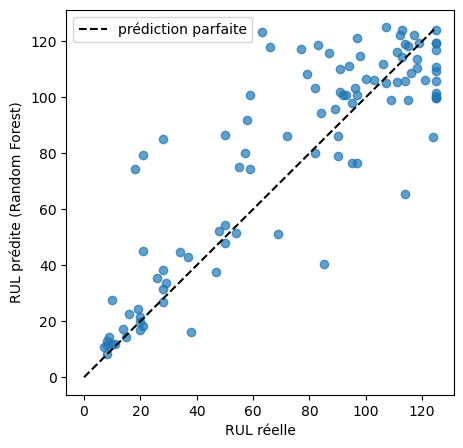

In [48]:
p_rf = np.clip(rf_final.predict(X_test), 0, 125)
plt.figure(figsize=(5, 5))
plt.scatter(y_test, p_rf, alpha=0.7)
plt.plot([0, 125], [0, 125], "k--", label="prédiction parfaite")
plt.xlabel("RUL réelle")
plt.ylabel("RUL prédite (Random Forest)")
plt.legend()
plt.show()

In [49]:
# 1) Trier pour que les décalages soient corrects
train = train.sort_values(["moteur", "cycle"]).reset_index(drop=True)
test = test.sort_values(["moteur", "cycle"]).reset_index(drop=True)

# 2) Variation de chaque capteur lissé sur les 10 derniers cycles
def ajouter_tendances(df):
    for c in capteurs:
        col = c + "_lisse"
        df[c + "_delta"] = (df[col] - df.groupby("moteur")[col].shift(10)).fillna(0)
    return df

train = ajouter_tendances(train)
test = ajouter_tendances(test)

# 3) Nouvelle liste de variables : capteurs lissés + tendances + âge du moteur
variables_v2 = variables_lisses + [c + "_delta" for c in capteurs] + ["cycle"]

# 4) Dernier cycle de chaque moteur de test
dernier = test.groupby("moteur").tail(1)
X_test2 = dernier[variables_v2]

# 5) Entraîner et mesurer
X_tout2, y_tout = train[variables_v2], train["RUL_cap"]
for nom, mod in [("Random Forest", RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)),
                 ("Gradient Boosting", HistGradientBoostingRegressor(random_state=42))]:
    mod.fit(X_tout2, y_tout)
    p = np.clip(mod.predict(X_test2), 0, 125)
    print(nom, ":", round(np.sqrt(mean_squared_error(y_test, p)), 1))

Random Forest : 14.8
Gradient Boosting : 14.0


In [50]:
# Modèle final (Gradient Boosting avec les variables de l'étape 8)
gb2 = HistGradientBoostingRegressor(random_state=42).fit(X_tout2, y_tout)
p_gb = np.clip(gb2.predict(X_test2), 0, 125)

print("Seuil | Détectés | Manqués | Fausses alertes")
for seuil in [20, 30, 40, 50]:
    alerte = p_gb < seuil          # le modèle déclenche une alerte
    proche = y_test < seuil        # le moteur est réellement à moins de 'seuil' cycles de la panne
    detectes = int((alerte & proche).sum())
    manques = int((~alerte & proche).sum())
    fausses = int((alerte & ~proche).sum())
    print(f"{seuil:>5} | {detectes:>8} | {manques:>7} | {fausses:>15}")

Seuil | Détectés | Manqués | Fausses alertes
   20 |       11 |       2 |               3
   30 |       19 |       6 |               1
   40 |       27 |       1 |               0
   50 |       30 |       0 |               3


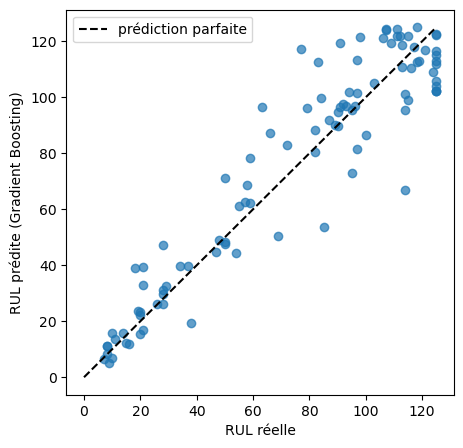

In [51]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, p_gb, alpha=0.7)
plt.plot([0, 125], [0, 125], "k--", label="prédiction parfaite")
plt.xlabel("RUL réelle")
plt.ylabel("RUL prédite (Gradient Boosting)")
plt.legend()
plt.savefig("resultat_final.png", dpi=150, bbox_inches="tight")
plt.show()

In [52]:
# Prédictions du modèle final pour tous les cycles des moteurs de test
sortie = test[["moteur", "cycle"]].copy()
sortie["RUL_predite"] = np.clip(gb2.predict(test[variables_v2]), 0, 125)

# Vraie RUL à chaque cycle : RUL finale (fichier NASA) + cycles restant à observer, plafonnée à 125
rul_finale = dict(zip(range(1, 101), rul_test["RUL"]))
dernier_cycle = test.groupby("moteur")["cycle"].transform("max")
sortie["RUL_reelle"] = (test["moteur"].map(rul_finale) + dernier_cycle - test["cycle"]).clip(upper=125)

sortie.to_csv("predictions_test.csv", index=False)
print(sortie.shape)
print(os.getcwd())

(13096, 4)
C:\Users\DELL


In [53]:
import os
print(os.getcwd())

C:\Users\DELL


In [54]:
import os
print([f for f in os.listdir() if f in ("app.py", "predictions_test.csv")])

['app.py', 'predictions_test.csv']


In [55]:
   print(os.getcwd())

C:\Users\DELL


In [56]:
from sklearn.model_selection import GroupKFold, cross_val_score

gkf = GroupKFold(n_splits=5)      # découpage en 5 groupes
groupes = train["moteur"]         # le numéro de moteur : les lignes d'un même moteur restent ensemble

modeles = {
    "Régression linéaire": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}

for nom, mod in modeles.items():
    scores = cross_val_score(mod, X_tout2, y_tout, groups=groupes, cv=gkf,
                             scoring="neg_root_mean_squared_error")
    erreurs = -scores             # sklearn donne l'erreur en négatif, on remet le signe
    print(nom, ":", round(erreurs.mean(), 1), "±", round(erreurs.std(), 1), "| par groupe :", erreurs.round(1))

Régression linéaire : 17.7 ± 0.5 | par groupe : [18.5 18.  17.  17.7 17.5]
Random Forest : 14.6 ± 0.9 | par groupe : [14.8 15.5 12.9 15.3 14.7]
Gradient Boosting : 14.3 ± 0.8 | par groupe : [14.4 15.2 12.8 14.6 14.6]
